# Deep Learning Project 1 

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np
import torch
import matplotlib.pyplot as plt
from dataset import CLASS_NAMES, load_train
from model import build_model, count_parameters
print('torch', torch.__version__, '| cuda available:', torch.cuda.is_available())

# the final model if it was trained, otherwise the first one
CKPT = '../runs/robust_w48/best.pt' if os.path.exists('../runs/robust_w48/best.pt') else '../runs/main/best.pt'
RUN = os.path.dirname(CKPT)
print('checkpoint:', CKPT)

Duplicate key in file WindowsPath('C:/Users/Administrator/AppData/Local/Programs/Python/Python312/Lib/site-packages/matplotlib/mpl-data/matplotlibrc'), line 814 ('font.family         : sans-serif')


Duplicate key in file WindowsPath('C:/Users/Administrator/AppData/Local/Programs/Python/Python312/Lib/site-packages/matplotlib/mpl-data/matplotlibrc'), line 815 ('font.sans-serif     : SimHei, SimSun, Microsoft YaHei, Microsoft-YaHei')


Duplicate key in file WindowsPath('C:/Users/Administrator/AppData/Local/Programs/Python/Python312/Lib/site-packages/matplotlib/mpl-data/matplotlibrc'), line 816 ('axes.unicode_minus  : False')


torch 2.5.1+cu121 | cuda available: True
checkpoint: ../runs/robust_w48/best.pt


## 1. Training images (32x32)

training set: (50000, 32, 32, 3) (50000,)


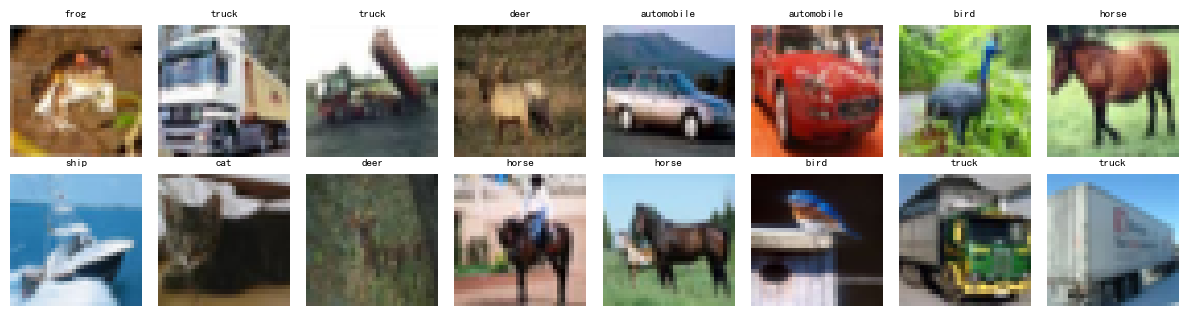

In [2]:
images, labels = load_train('../data')
print('training set:', images.shape, labels.shape)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(images[i])
    ax.set_title(CLASS_NAMES[labels[i]], fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig('../figures/samples.png', dpi=150)
plt.show()

## 2. Model and parameter count

In [3]:
model = build_model(torch.load(CKPT, map_location='cpu', weights_only=False)['model'])
print(model)
print()
print(f'number of trainable parameters: {count_parameters(model):,}')
print('limit of the competition        :   5,000,000')

ResNetCIFAR(
  (stem): Sequential(
    (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (stages): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(48, eps=1e

In [4]:
# parameters per part of the network
for name, module in [('stem', model.stem), ('stage 1', model.stages[0:2]),
                     ('stage 2', model.stages[2:4]), ('stage 3', model.stages[4:6]),
                     ('stage 4', model.stages[6:8])]:
    n = sum(p.numel() for p in module.parameters())
    print(f'{name:8s} {n:>10,}')

stem          1,392
stage 1      83,328
stage 2     252,208
stage 3     992,992
stage 4   3,331,200


## 3. Training curves

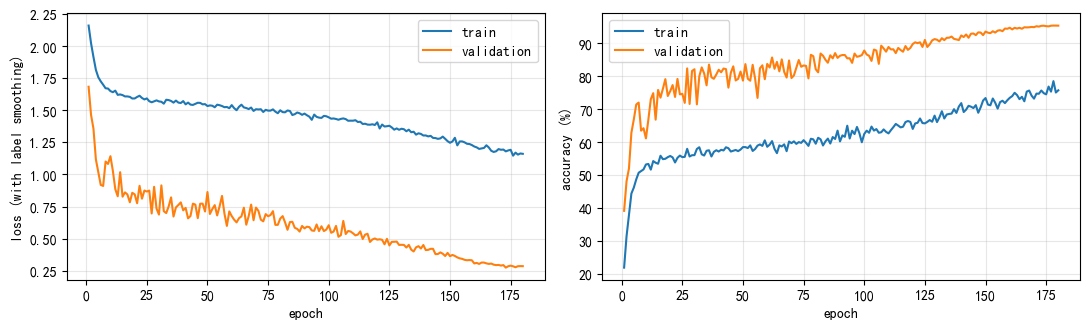

best validation accuracy: 95.34%


In [5]:
import csv
rows = list(csv.DictReader(open(RUN + '/metrics.csv')))
epochs = [int(r['epoch']) for r in rows]
tr_loss = [float(r['train_loss']) for r in rows]
va_loss = [float(r['val_loss']) for r in rows]
tr_acc = [float(r['train_acc']) * 100 for r in rows]
va_acc = [float(r['val_acc']) * 100 for r in rows]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(epochs, tr_loss, label='train')
ax[0].plot(epochs, va_loss, label='validation')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss (with label smoothing)'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(epochs, tr_acc, label='train')
ax[1].plot(epochs, va_acc, label='validation')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('accuracy (%)'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout()
plt.savefig('../figures/curves_main.png', dpi=150)
plt.show()
print('best validation accuracy: %.2f%%' % max(va_acc))

## 4. Final accuracy on the validation split

In [6]:
from train import evaluate

ckpt = torch.load(CKPT, map_location='cuda', weights_only=False)
model = build_model(ckpt['model']).cuda()
model.load_state_dict(ckpt['state_dict'])

order = np.random.RandomState(42).permutation(len(labels))
x_val, y_val = images[order[:5000]], labels[order[:5000]]

_, acc = evaluate(model, x_val, y_val, device='cuda')
print(f'validation accuracy (no TTA): {acc * 100:.2f}%')
print(f'number of trainable parameters: {count_parameters(model):,}')

validation accuracy (no TTA): 95.34%
number of trainable parameters: 4,664,330


## 5. Submission

In [7]:
import csv
from collections import Counter
rows = list(csv.DictReader(open('../data/submission.csv')))
print('rows in submission:', len(rows))
print('columns:', list(rows[0].keys()))
print('first rows:', rows[:3])
print('class distribution:', dict(sorted(Counter(int(r['label']) for r in rows).items())))

rows in submission: 2000
columns: ['id', 'label']
first rows: [{'id': '0', 'label': '6'}, {'id': '1', 'label': '3'}, {'id': '2', 'label': '3'}]
class distribution: {0: 174, 1: 213, 2: 199, 3: 221, 4: 187, 5: 208, 6: 185, 7: 203, 8: 214, 9: 196}


## 6. Where do the test images come from?

Download the reference sets once with `python src/prepare_cifar_ref.py`.
The first two cells check the data, the third one measures the accuracy on a
public set with the same kind of shift as the leaderboard set.

In [8]:
ref = '../diag'
if os.path.exists(ref + '/cifar_train_x.npy'):
    official = np.load(ref + '/cifar_train_x.npy')
    table = {a.tobytes(): i for i, a in enumerate(official)}
    hits = sum(1 for a in images if a.tobytes() in table)
    print(f'training images that are identical to the official CIFAR-10 train set: {hits} / {len(images)}')
else:
    print('run src/prepare_cifar_ref.py first')

training images that are identical to the official CIFAR-10 train set: 50000 / 50000


In [9]:
from dataset import load_test
test_images, test_ids = load_test('../data')
for name in ['cifar_test_x.npy', 'cifar10.1_v6_data.npy']:
    if not os.path.exists(ref + '/' + name):
        print(name, 'missing'); continue
    other = np.load(ref + '/' + name)
    table = {a.tobytes(): i for i, a in enumerate(other)}
    hits = sum(1 for a in test_images if a.tobytes() in table)
    print(f'test images that appear in {name:22s}: {hits} / {len(test_images)}')

test images that appear in cifar_test_x.npy      : 0 / 2000
test images that appear in cifar10.1_v6_data.npy : 0 / 2000


In [10]:
import subprocess
out = subprocess.run([sys.executable, '../src/robust_eval.py', '--checkpoints', CKPT,
                      '--tta'], capture_output=True, text=True)
print(out.stdout or out.stderr)

1 checkpoint(s):
  + ../runs/robust_w48/best.pt  (resnet18_w48, epoch 178)



## 7. Prediction configurations (Table 5 of the report)

Test-time augmentation and averaging two networks. This takes about a minute on
a GPU; it writes `report/configs.json`.

In [11]:
out = subprocess.run([sys.executable, '../src/config_table.py',
                      '--data-dir', '../data', '--out', 'report/configs.json'],
                     capture_output=True, text=True)
print(out.stdout or out.stderr)

A only, no TTA               val=0.9556  cifar10=0.9497  cifar10.1=0.8855
A only, flip TTA             val=0.9566  cifar10=0.9538  cifar10.1=0.8850
B only, no TTA               val=0.9532  cifar10=0.9550  cifar10.1=0.8930
B only, flip TTA             val=0.9562  cifar10=0.9570  cifar10.1=0.9010
B only, flip + 2 shifts      val=0.9560  cifar10=0.9593  cifar10.1=0.9005
B only, 6 views              val=0.9568  cifar10=0.9596  cifar10.1=0.9030
A + B, no TTA                val=0.9610  cifar10=0.9609  cifar10.1=0.9035
A + B, 6 views each          val=0.9622  cifar10=0.9653  cifar10.1=0.9065
wrote report/configs.json

